# Chapitre 8 - Exercices 8.1 à 8.4

* **8.1** - Inégalité de Jensen et maximum de $R(\theta', \theta)$.
* **8.2** - L'étape E comme maximisation sous contrainte (multiplicateurs de Lagrange).
* **8.3** - Estimation de densités marginales à partir d'un échantillonneur de Gibbs.
* **8.4** - Bagging d'un lisseur linéaire avec le bootstrap paramétrique.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## Exercice 8.1 : Jensen et maximisation de $E_q \log[r(Y)/q(Y)]$

**Énoncé.** Soient $r$ et $q$ deux densités de probabilité. L'inégalité de Jensen affirme
que, pour une variable aléatoire $X$ et une fonction convexe $\varphi$,
$E[\varphi(X)] \ge \varphi(E[X])$. En déduire que

$$E_q\log\frac{r(Y)}{q(Y)} \qquad \text{(éq. (8.61) du livre)}$$

(espérance prise pour $Y$ de densité $q$) est maximale, comme fonction de $r$, lorsque
$r = q$. En déduire l'inégalité $R(\theta, \theta) \ge R(\theta', \theta)$ utilisée
après l'équation (8.46).

### Rappels

* Une fonction $\varphi$ est **convexe** si
  $\varphi(tx + (1-t)y) \le t\varphi(x) + (1-t)\varphi(y)$ pour $t \in [0,1]$ ; une
  fonction deux fois dérivable est convexe si et seulement si $\varphi'' \ge 0$.
  Ici $\varphi(u) = -\log u$ sur $]0, +\infty[$ : $\varphi''(u) = 1/u^2 > 0$, donc
  $-\log$ est **strictement** convexe.
* Dans l'algorithme EM (section 8.5.2), $R(\theta', \theta) = E[\ell_1(\theta'; Z^m\mid Z)
  \mid Z, \theta]$, où $\ell_1(\theta'; Z^m\mid Z) = \log\Pr(Z^m\mid Z, \theta')$ :
  c'est l'espérance, sous la loi conditionnelle de paramètre $\theta$, du logarithme de
  la densité conditionnelle de paramètre $\theta'$.

### Solution : maximum en $r = q$

Notons $A = \{y : q(y) > 0\}$ le support de $q$. Sous $q$, $Y \in A$ presque sûrement et
la variable $X = r(Y)/q(Y)$ est bien définie, à valeurs dans $[0, +\infty[$ (si $X$ peut
valoir 0, $\log X = -\infty$ et l'inégalité ci-dessous est triviale).

1. On applique Jensen à la fonction convexe $\varphi = -\log$ :
   $E_q[-\log X] \ge -\log E_q[X]$, c'est-à-dire
   $$E_q\log\frac{r(Y)}{q(Y)} \le \log E_q\Big[\frac{r(Y)}{q(Y)}\Big].$$
2. On calcule l'espérance de droite par la formule de transfert :
   $$E_q\Big[\frac{r(Y)}{q(Y)}\Big] = \int_A \frac{r(y)}{q(y)}\,q(y)\,dy = \int_A r(y)\,dy
   \le \int r(y)\,dy = 1.$$
3. Le logarithme étant croissant, $\log E_q[r/q] \le \log 1 = 0$. Donc, **pour toute
   densité** $r$ :
   $$E_q\log\frac{r(Y)}{q(Y)} \le 0.$$
4. Pour $r = q$, le rapport vaut 1 et $E_q\log 1 = 0$ : la borne est atteinte. Le maximum
   sur $r$ vaut donc $0$ et il est atteint en $r = q$.

**Unicité.** $-\log$ étant strictement convexe, l'égalité dans Jensen impose que $X$ soit
presque sûrement constante, $r = c\,q$ sur $A$ ; l'égalité dans l'étape 2 impose
$\int_A r = 1$, d'où $c = 1$ : $r = q$ presque partout.

> **Remarque.** La quantité $-E_q\log(r/q) = \int q\log(q/r) \ge 0$ est la **divergence
> de Kullback-Leibler** $\mathrm{KL}(q\,\|\,r)$ : nous venons de démontrer
> l'**inégalité de Gibbs**, $\mathrm{KL}(q\|r) \ge 0$ avec égalité ssi $r = q$.

### Conséquence pour EM

Fixons $\theta$ et $\theta'$. Notons $q(z^m) = \Pr(z^m\mid Z, \theta)$ et
$r(z^m) = \Pr(z^m\mid Z, \theta')$, deux densités (ou fonctions de masse) en $z^m$. Par
définition de $R$ et par linéarité de l'espérance,

$$R(\theta', \theta) - R(\theta, \theta) = E_q[\log r(Z^m)] - E_q[\log q(Z^m)]
= E_q\log\frac{r(Z^m)}{q(Z^m)} \le 0,$$

d'après ce qui précède (le raisonnement est identique avec des sommes pour des variables
discrètes). Donc $R(\theta, \theta) \ge R(\theta', \theta)$ pour tout $\theta'$.

### Vérification numérique 1 : lois discrètes

On tire une loi $q$ sur 6 points et 2000 lois $r$ aléatoires ; toutes vérifient
$E_q\log(r/q) \le 0$, et la valeur se rapproche de 0 quand $r$ se rapproche de $q$.

In [2]:
q = rng.dirichlet(np.ones(6))
vals, dists = [], []
for _ in range(2000):
    t = rng.rand()                                   # r = mélange entre q et une loi aléatoire
    r = (1 - t) * q + t * rng.dirichlet(np.ones(6))
    vals.append(np.sum(q * np.log(r / q)))
    dists.append(np.abs(r - q).sum())
print("max de E_q log(r/q) sur les 2000 lois : %.2e" % max(vals))

max de E_q log(r/q) sur les 2000 lois : -1.62e-09


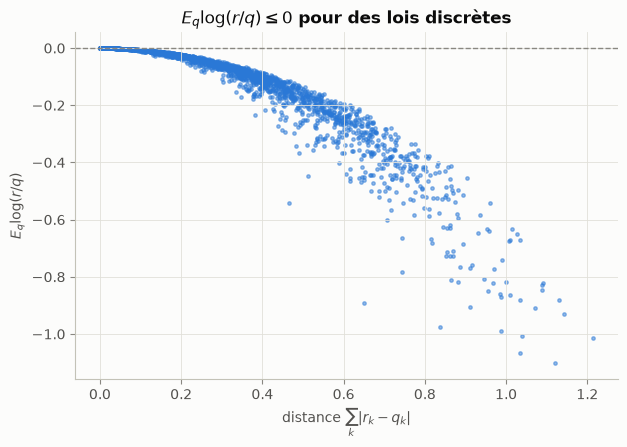

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(dists, vals, s=6, color=BLUE, alpha=0.5)
ax.axhline(0, color=GRAY, ls="--", lw=1)
ax.set(title=r"$E_q\log(r/q) \leq 0$ pour des lois discrètes",
       xlabel=r"distance $\sum_k |r_k - q_k|$", ylabel=r"$E_q\log(r/q)$")
plt.show()

### Vérification numérique 2 : lois normales

Pour $q = N(0, 1)$ et $r_t = N(t, s^2)$, un calcul direct donne
$E_q\log(r_t/q) = -\log s - \frac{1 + t^2}{2s^2} + \frac12$, maximal (et nul) en
$(t, s) = (0, 1)$. On compare avec une estimation de Monte-Carlo.

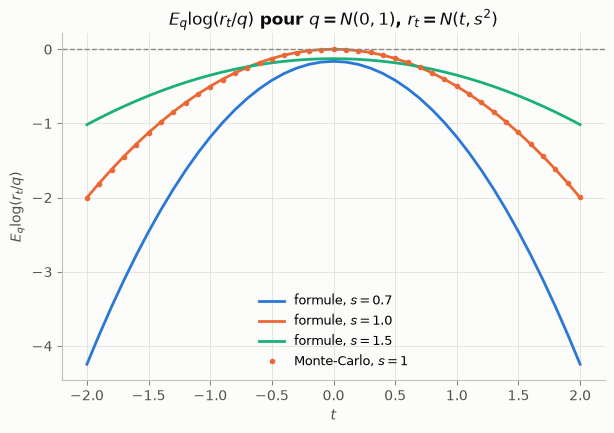

In [4]:
Yq = rng.randn(200000)
ts = np.linspace(-2, 2, 41)
mc = [np.mean(stats.norm.logpdf(Yq, t, 1) - stats.norm.logpdf(Yq)) for t in ts]
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, s_ in zip(COLORS, [0.7, 1.0, 1.5]):
    ax.plot(ts, -np.log(s_) - (1 + ts ** 2) / (2 * s_ ** 2) + 0.5, color=c,
            label="formule, $s = %.1f$" % s_)
ax.plot(ts, mc, "o", color=COLORS[1], ms=3, label="Monte-Carlo, $s = 1$")
ax.axhline(0, color=GRAY, ls="--", lw=1)
ax.set(title=r"$E_q\log(r_t/q)$ pour $q=N(0,1)$, $r_t = N(t, s^2)$", xlabel="$t$",
       ylabel=r"$E_q\log(r_t/q)$")
ax.legend()
plt.show()

### Vérification numérique 3 : la fonction $R$ du mélange

Pour le mélange de deux gaussiennes du cours (tableau 8.1), $Z^m = (\Delta_1, \dots,
\Delta_N)$ et, les $\Delta_i$ étant indépendants sachant les données,
$R(\theta', \theta) = \sum_i \big[\gamma_i(\theta)\log\gamma_i(\theta') +
(1 - \gamma_i(\theta))\log(1 - \gamma_i(\theta'))\big]$. On fixe $\theta$ et on fait varier
$\mu_1'$ dans $\theta'$.

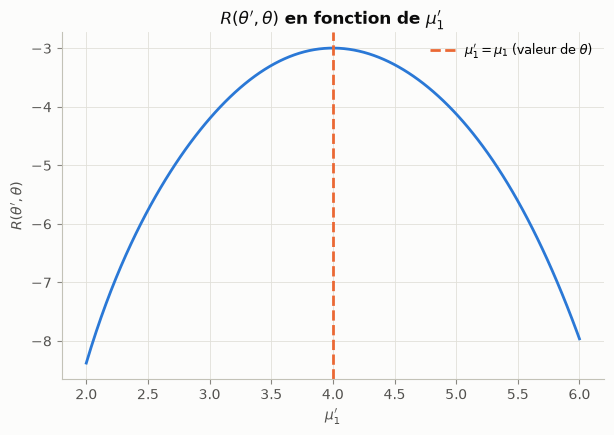

argmax numérique : 4.010


In [5]:
y = inf.MIXTURE_DATA
theta = (4.0, 1.0, 1.5, 1.0, 0.5)                    # (mu1, var1, mu2, var2, pi)

def R_mix(theta_new, theta_old):
    g, gn = inf.responsibilities(y, theta_old), inf.responsibilities(y, theta_new)
    return np.sum(g * np.log(gn) + (1 - g) * np.log(1 - gn))

m1 = np.linspace(2, 6, 200)
Rv = [R_mix((m, 1.0, 1.5, 1.0, 0.5), theta) for m in m1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(m1, Rv, color=BLUE)
ax.axvline(theta[0], color=ORANGE, ls="--", label=r"$\mu_1' = \mu_1$ (valeur de $\theta$)")
ax.set(title=r"$R(\theta', \theta)$ en fonction de $\mu_1'$", xlabel=r"$\mu_1'$",
       ylabel=r"$R(\theta', \theta)$")
ax.legend()
plt.show()
print("argmax numérique : %.3f" % m1[np.argmax(Rv)])

> **À retenir.** $E_q\log(r/q) = -\mathrm{KL}(q\|r) \le 0$, avec égalité ssi $r = q$.
> Appliqué aux lois conditionnelles des données latentes, cela donne
> $R(\theta', \theta) \le R(\theta, \theta)$ : c'est la clé de la croissance de la
> vraisemblance au fil des itérations EM (éq. (8.47)).

## Exercice 8.2 : L'étape E par multiplicateurs de Lagrange

**Énoncé.** On maximise la fonction (8.48),
$F(\theta', \tilde P) = E_{\tilde P}[\ell_0(\theta'; T)] - E_{\tilde P}[\log\tilde P(Z^m)]$,
par rapport aux lois $\tilde P(Z^m)$ vérifiant $\tilde P(Z^m) \ge 0$ et
$\sum_{Z^m}\tilde P(Z^m) = 1$. Montrer, à l'aide de multiplicateurs de Lagrange, que la
solution est la loi conditionnelle $\tilde P(Z^m) = \Pr(Z^m\mid Z, \theta')$, comme dans
(8.49).

### Rappels

* **Multiplicateurs de Lagrange.** Pour maximiser une fonction différentiable $f(p)$
  sous une contrainte d'égalité $g(p) = 0$, on introduit le lagrangien
  $\mathcal L(p, \lambda) = f(p) - \lambda g(p)$ ; en un extremum intérieur, il existe
  $\lambda$ tel que $\nabla_p\mathcal L = 0$.
* On suppose $Z^m$ discret, à valeurs dans un ensemble fini $\{z_1, \dots, z_L\}$, et l'on
  note $p_\ell = \tilde P(z_\ell)$. La log-vraisemblance complète vaut
  $\ell_0(\theta'; T) = \log\Pr(Z, Z^m\mid\theta')$ ; posons
  $a_\ell = \log\Pr(Z, z_\ell\mid\theta')$ (nombre fixé, $\theta'$ et $Z$ étant fixés).

### Solution

**Écriture de $F$.** Par définition de l'espérance sous $\tilde P$ :

$$F(p) = \sum_{\ell=1}^L p_\ell\,a_\ell - \sum_{\ell=1}^L p_\ell\log p_\ell
\qquad (\text{avec } 0\log 0 = 0).$$

**Lagrangien.** On ignore d'abord la contrainte $p_\ell \ge 0$ (on vérifiera qu'elle est
satisfaite) : $\mathcal L(p, \lambda) = \sum_\ell p_\ell a_\ell - \sum_\ell p_\ell\log p_\ell
- \lambda\big(\sum_\ell p_\ell - 1\big)$.

**Condition du premier ordre.** Pour chaque $\ell$, comme
$\frac{d}{dp}(p\log p) = \log p + 1$ :

$$\frac{\partial\mathcal L}{\partial p_\ell} = a_\ell - \log p_\ell - 1 - \lambda = 0
\iff p_\ell = e^{-(1+\lambda)}\,e^{a_\ell} = C\,\Pr(Z, z_\ell\mid\theta').$$

**Normalisation.** La contrainte $\sum_\ell p_\ell = 1$ donne
$C = 1/\sum_\ell\Pr(Z, z_\ell\mid\theta') = 1/\Pr(Z\mid\theta')$ (formule des
probabilités totales). Donc

$$p_\ell = \frac{\Pr(Z, z_\ell\mid\theta')}{\Pr(Z\mid\theta')} = \Pr(z_\ell\mid Z, \theta').$$

Toutes les $p_\ell$ sont strictement positives : la contrainte d'inégalité est bien
inactive.

**C'est un maximum.** La fonction $p \mapsto \sum_\ell p_\ell a_\ell$ est linéaire et
$p \mapsto -\sum_\ell p_\ell\log p_\ell$ est strictement concave (sa hessienne est
diagonale, de termes $-1/p_\ell < 0$). $F$ est donc strictement concave sur le simplexe
(ensemble convexe) : le point critique trouvé est **l'unique maximum global**.

**Valeur au maximum.** En remplaçant, $a_\ell - \log p_\ell = \log\Pr(Z\mid\theta')$ pour
tout $\ell$, d'où
$F = \sum_\ell p_\ell\log\Pr(Z\mid\theta') = \log\Pr(Z\mid\theta') = \ell(\theta'; Z)$ :
au maximum, $F$ coïncide avec la log-vraisemblance observée.

> **Remarque.** Plus directement, $F(p) = \ell(\theta'; Z) - \mathrm{KL}\big(p\,\|\,
> \Pr(\cdot\mid Z, \theta')\big)$, et l'exercice 8.1 conclut aussi.

### Vérification numérique : maximisation sur le simplexe

On tire des valeurs $\Pr(Z, z_\ell\mid\theta')$ arbitraires pour $L = 6$ et on maximise
$F$ numériquement (SLSQP, sous contraintes).

In [6]:
L = 6
joint = rng.rand(L) * 0.1                             # Pr(Z, z_l | theta') (non normalisé)
a = np.log(joint)
negF = lambda p: -(np.sum(p * a) - np.sum(p * np.log(np.clip(p, 1e-300, None))))
res = optimize.minimize(negF, np.full(L, 1 / L), method="SLSQP", bounds=[(0, 1)] * L,
                        constraints=[{"type": "eq", "fun": lambda p: p.sum() - 1}],
                        options={"ftol": 1e-14})
print("maximiseur numérique  :", np.round(res.x, 4))
print("Pr(z_l | Z, theta')   :", np.round(joint / joint.sum(), 4))
print("F max = %.6f   log Pr(Z|theta') = %.6f" % (-res.fun, np.log(joint.sum())))

maximiseur numérique  : [0.2656 0.2653 0.234  0.184  0.0019 0.0491]
Pr(z_l | Z, theta')   : [0.2656 0.2653 0.234  0.184  0.0019 0.0491]
F max = -1.040352   log Pr(Z|theta') = -1.040352


### Illustration sur le mélange

Pour le mélange, on restreint $\tilde P$ aux lois produits
$\tilde P(\Delta) = \prod_i\gamma_i^{\Delta_i}(1-\gamma_i)^{1-\Delta_i}$ (la loi
conditionnelle exacte est de cette forme). $F$ se décompose en une somme de termes
$F_i(\gamma_i) = \gamma_i\log[\pi\phi_2(y_i)] + (1-\gamma_i)\log[(1-\pi)\phi_1(y_i)]
- \gamma_i\log\gamma_i - (1-\gamma_i)\log(1-\gamma_i)$, chacun maximal en la
responsabilité $\hat\gamma_i$ (8.42). On le vérifie pour quelques observations
proches de la zone de recouvrement des deux composantes, avec
$\theta' = (\mu_1, \sigma_1^2, \mu_2, \sigma_2^2, \pi) = (4, 2, 1{,}5, 2, 0{,}5)$.

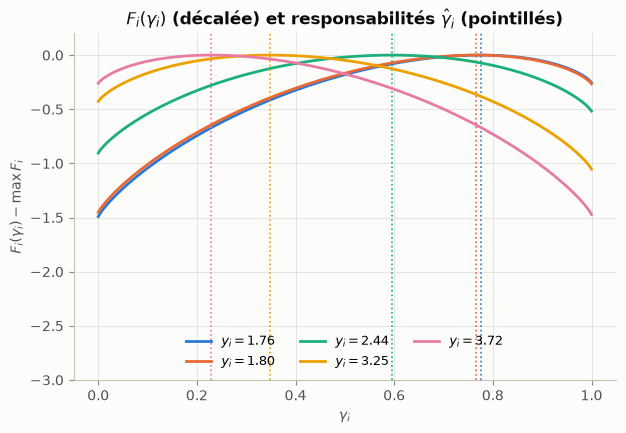

In [7]:
theta_p = (4.0, 2.0, 1.5, 2.0, 0.5)      # un paramètre theta' quelconque
mu1, v1, mu2, v2, pi = theta_p
gg = np.linspace(1e-4, 1 - 1e-4, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, i in zip(COLORS, [8, 9, 10, 11, 12]):
    yi = np.sort(y)[i]
    A2 = np.log(pi * inf.normal_pdf(yi, mu2, v2))
    A1 = np.log((1 - pi) * inf.normal_pdf(yi, mu1, v1))
    Fi = gg * A2 + (1 - gg) * A1 - gg * np.log(gg) - (1 - gg) * np.log(1 - gg)
    gi = inf.responsibilities(np.array([yi]), theta_p)[0]
    ax.plot(gg, Fi - Fi.max(), color=c, label="$y_i = %.2f$" % yi)
    ax.axvline(gi, color=c, ls=":", lw=1.2)
ax.set(title=r"$F_i(\gamma_i)$ (décalée) et responsabilités $\hat\gamma_i$ (pointillés)",
       xlabel=r"$\gamma_i$", ylabel=r"$F_i(\gamma_i) - \max F_i$", ylim=(-3, 0.2))
ax.legend(loc="lower center", ncol=3)
plt.show()

> **À retenir.** À $\theta'$ fixé, le maximiseur de $F(\theta', \cdot)$ est la loi
> conditionnelle des données latentes $\Pr(Z^m\mid Z, \theta')$ : c'est exactement ce que
> calcule l'étape E, et la valeur atteinte est la log-vraisemblance observée.

## Exercice 8.3 : Densités marginales à partir de Gibbs

**Énoncé.** Justifier l'estimateur (8.50) de la densité marginale de $U_k$ :

$$\widehat{\Pr}_{U_k}(u) = \frac{1}{M - m + 1}\sum_{t=m}^M
\Pr\big(u\mid U_\ell^{(t)}, \ell \ne k\big),$$

en utilisant la relation $\Pr(A) = \int\Pr(A\mid B)\,d\Pr(B)$.

### Rappels

* **Formule des probabilités totales / conditionnement** : si $(U, V)$ a une densité,
  la densité marginale de $U$ est $p_U(u) = \int p(u\mid v)\,p_V(v)\,dv
  = E_V[p(u\mid V)]$. C'est la relation de l'énoncé avec $A = \{U_k \in du\}$ et
  $B = (U_\ell)_{\ell \ne k}$.
* **Loi des grands nombres pour les chaînes de Markov (théorème ergodique)** : si une
  chaîne $(V^{(t)})$ admet la loi stationnaire $\nu$ (et sous des hypothèses de
  régularité), alors pour toute fonction $g$ intégrable,
  $\frac1n\sum_{t=1}^n g(V^{(t)}) \to E_\nu[g(V)]$ presque sûrement, même si les
  $V^{(t)}$ ne sont pas indépendants.

### Solution

1. Notons $V = (U_\ell)_{\ell\ne k}$. Par la relation rappelée (conditionnement par
   $V$) :
   $$p_{U_k}(u) = \int \Pr(u\mid V = v)\,d\Pr(v) = E\big[\Pr(u\mid V)\big],$$
   où l'espérance porte sur la loi **marginale** de $V$ sous la loi jointe visée.
2. Après la période de chauffe ($t \ge m$), l'échantillonneur de Gibbs a (approximativement)
   atteint sa loi stationnaire, qui est la loi jointe de $(U_1, \dots, U_K)$ ; donc
   chaque $V^{(t)} = (U_\ell^{(t)})_{\ell\ne k}$ suit (approximativement) la loi marginale
   de $V$.
3. Pour $u$ fixé, appliquons le théorème ergodique à $g(v) = \Pr(u\mid V = v)$ : la
   moyenne
   $$\frac{1}{M - m + 1}\sum_{t=m}^M \Pr(u\mid V^{(t)})$$
   converge vers $E[\Pr(u\mid V)] = p_{U_k}(u)$ quand $M \to \infty$. C'est l'estimateur
   (8.50), qui est donc convergent. On écarte les $m - 1$ premières itérations pour
   limiter le biais dû au point de départ.

**Pourquoi est-il meilleur qu'un histogramme des $U_k^{(t)}$ ?** L'histogramme (ou un
estimateur à noyau) moyenne des fonctions indicatrices $\mathbb 1\{U_k^{(t)} \in \text{case}\}$
dont l'espérance conditionnelle sachant $V^{(t)}$ est exactement la probabilité
conditionnelle. Remplacer une variable par son espérance conditionnelle ne change pas
la moyenne mais diminue la variance (décomposition
$\mathrm{Var}(X) = \mathrm{Var}(E[X\mid V]) + E[\mathrm{Var}(X\mid V)]$) : c'est le
principe de **Rao-Blackwell**. De plus, (8.50) est une fonction lisse de $u$, sans
paramètre de lissage à choisir.

### Vérification numérique

Gibbs sur un couple gaussien centré réduit de corrélation $\rho = 0{,}8$ :
$U_1\mid U_2 \sim N(\rho U_2, 1 - \rho^2)$. La vraie marginale de $U_1$ est $N(0, 1)$.
On compare l'estimateur (8.50) à un histogramme des $U_1^{(t)}$.

In [8]:
def gibbs_gauss(T, rho, rng):
    U = np.zeros((T, 2)); u1, u2 = 3.0, -3.0
    for t in range(T):
        u1 = rho * u2 + np.sqrt(1 - rho ** 2) * rng.randn()
        u2 = rho * u1 + np.sqrt(1 - rho ** 2) * rng.randn()
        U[t] = u1, u2
    return U

rho, m_burn, M = 0.8, 50, 550
U = gibbs_gauss(M, rho, rng)
grid = np.linspace(-4, 4, 200)
dens_rb = stats.norm.pdf(grid[:, None], rho * U[m_burn:, 1][None, :],
                         np.sqrt(1 - rho ** 2)).mean(axis=1)

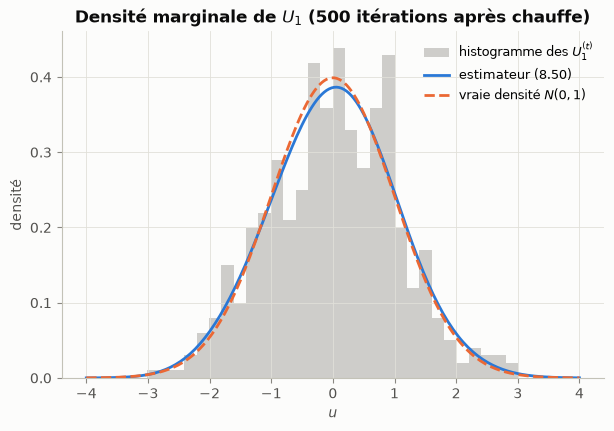

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(U[m_burn:, 0], bins=30, density=True, color=GRAY, alpha=0.4,
        label="histogramme des $U_1^{(t)}$")
ax.plot(grid, dens_rb, color=BLUE, label="estimateur (8.50)")
ax.plot(grid, stats.norm.pdf(grid), color=ORANGE, ls="--", label="vraie densité $N(0,1)$")
ax.set(title="Densité marginale de $U_1$ (500 itérations après chauffe)", xlabel="$u$",
       ylabel="densité")
ax.legend()
plt.show()

Répétons l'expérience 200 fois et comparons l'erreur quadratique intégrée
$\int(\hat p - p)^2$ de l'estimateur (8.50) et d'un estimateur à noyau gaussien
(scipy, fenêtre de Scott).

In [10]:
ise_rb, ise_kde = [], []
for r in range(200):
    U = gibbs_gauss(M, rho, rng)
    p_rb = stats.norm.pdf(grid[:, None], rho * U[m_burn:, 1][None, :],
                          np.sqrt(1 - rho ** 2)).mean(axis=1)
    p_kde = stats.gaussian_kde(U[m_burn:, 0])(grid)
    dx = grid[1] - grid[0]
    ise_rb.append(np.sum((p_rb - stats.norm.pdf(grid)) ** 2) * dx)
    ise_kde.append(np.sum((p_kde - stats.norm.pdf(grid)) ** 2) * dx)
print("Erreur quadratique intégrée moyenne : (8.50) %.5f | noyau %.5f"
      % (np.mean(ise_rb), np.mean(ise_kde)))

Erreur quadratique intégrée moyenne : (8.50) 0.00108 | noyau 0.00289
